### Projet pluridisciplinaire

# TP3 - Fonctions mathématiques et résolution d'équation

Dans ce TP, le but est d'approfondir l'utilisation des **fonctions mathématiques** en Sage et d'étudier des questions de résolutions d'équations

## Les fonctions mathématiques dans Sage

Comme nous l'avons vu au 1er TP, Sage permet de définir simplement des
fonctions mathématiques à l'aide d'expressions symboliques comme suit :

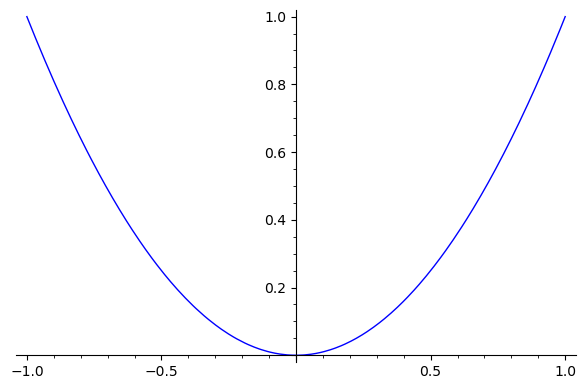

In [3]:
f(x) = x^2
plot(f)

Ces fonctions possèdent un certain nombre de méthodes (comme
`integrate`, `derivative`, etc.) listées en tapant `f.` et tabulation.

In [4]:
f.integrate(x)

x |--> 1/3*x^3

In [5]:
f.derivative(x)

x |--> 2*x

En particulier, il est possible d'obtenir le développement de Taylor à l'ordre $N$ d'une fonction à l'aide de la commande `taylor`.

**Exécutez la cellule ci-dessous pour obtenir la documentation de la méthode et les exemples d'utilisations**.

In [17]:
f.taylor?

**Définissez une fonction $g$ non polynomiale, continue et dérivable en 0
(par exemple $\sin(x)$). Tracez cette fonction ainsi que son développement
limité à l'ordre 1, 2 et 3 au voisinage de 0 (avec des couleurs différentes).**

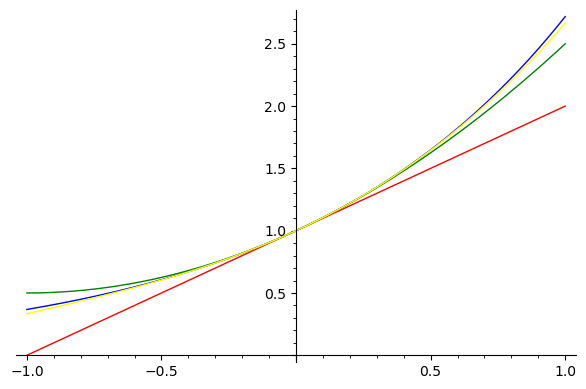

In [22]:
g(x) = exp(x)
plot(g)+plot(taylor(g(x),x, 0, 1), color ="red")+plot(taylor(g(x),x, 0, 2), color ="green")+plot(taylor(g(x),x, 0, 3), color ="yellow")

## Résolution exacte et points d'intersection

Sage permet notamment de résoudre de manière exacte de nombreuses équations.
Dans l'exemple ci-après, on considère une fonction polynomiale dont on
cherche les racines. **Exécutez cet exemple.**


In [23]:
f(x) = x^4 - x^2 - x - 1
solve(f(x) == 0, x)

[x == -1/6*(1/2)^(1/3)*(3*sqrt(31)*sqrt(3) + 29)^(1/3)*(I*sqrt(3) + 1) - 1/3*(1/2)^(2/3)*(-I*sqrt(3) + 1)/(3*sqrt(31)*sqrt(3) + 29)^(1/3) + 1/3, x == -1/6*(1/2)^(1/3)*(3*sqrt(31)*sqrt(3) + 29)^(1/3)*(-I*sqrt(3) + 1) - 1/3*(1/2)^(2/3)*(I*sqrt(3) + 1)/(3*sqrt(31)*sqrt(3) + 29)^(1/3) + 1/3, x == 1/3*(1/2)^(1/3)*(3*sqrt(31)*sqrt(3) + 29)^(1/3) + 2/3*(1/2)^(2/3)/(3*sqrt(31)*sqrt(3) + 29)^(1/3) + 1/3, x == -1]

La fonction `solve` renvoie la liste des solutions de notre équation. Il est également possible de résoudre des systèmes d'équations (même non linéaires) comme suit : 

In [49]:
var('x1 x2 x3')
solve([x1 + x2 - x3 == 0, x2 - x3 == -3 * x1^2 + x3, x3 == 6 * x2 - x1], x1, x2, x3)

[[x1 == 0, x2 == 0, x3 == 0], [x1 == (4/5), x2 == (8/25), x3 == (28/25)]]

**Remarque** : L'instruction initiale permet de définir symboliquement `x1`, `x2` et `x3`
comme des inconnues. Elle est indispensable pour définir le système qu'on souhaite résoudre.

**Donnez un système permettant de trouver le (ou les) points d'intersections de 2 cercles définis par :**
 * un cercle de centre $(0, 0)$ et de rayon 2
 * un cercle de centre $(0.5, 0.75)$ et de rayon 2.

**Résolvez ce système puis tracez les cercles (en bleu) et leurs points d'intersection (en rouge) (avec `circle` et `poind2d` en faisant un copier coller des valeurs données par sage) pour vérifier votre solution.**

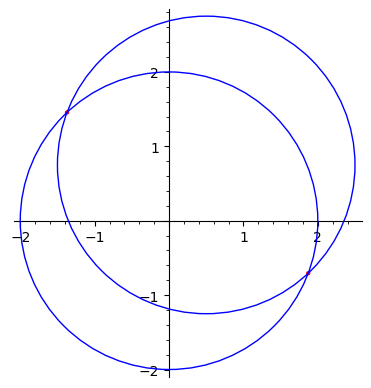

In [72]:
var('x4 y4')
s = solve([x4**2+y4**2==4, (x4-0.5)**2+(y4-0.75)**2==4], x4,y4)
circle((0,0),2)+circle((0.5,0.75),2)+point2d((-27/104*sqrt(39) + 1/4, 9/52*sqrt(39) + 3/8), color="red")+point2d((27/104*sqrt(39) + 1/4, -9/52*sqrt(39) + 3/8), color="red")

Si maintenant le deuxième cercle a pour centre $(3, 5)$ et toujours rayon 2,
**tracez les cercles; voyez-vous un point d'intersection ?**

*Remarque : les questions qui ne demandent pas de code sont là pour vous faire réfléchir,
pas besoin d'écrire une réponse.*

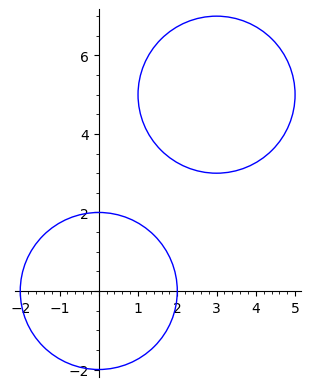

In [73]:
circle((0,0),2)+circle((3,5),2)

**Résolvez l'équation formelle pour calculer les points d'intersection avec Sage.**

Sage trouve des solutions, pourquoi ne les voit-on pas sur le dessin ?

In [75]:
var('x4 y4')
s = solve([x4**2+y4**2==4, (x4-3)**2+(y4-5)**2==4], x4,y4)
print(s)

[
[x4 == -15/34*I*sqrt(17) + 3/2, y4 == 9/34*I*sqrt(17) + 5/2],
[x4 == 15/34*I*sqrt(17) + 3/2, y4 == -9/34*I*sqrt(17) + 5/2]
]


**Comment faire pour tester et traiter automatiquement les valeurs renvoyées par `solve` ?**

En rajoutant un paramètre supplémentaire `solution_dict = True`, on peut récupérer les solutions sous forme de *liste de dictionnaires*

In [76]:
D = solve([x1 + x2 - x3 == 0, x2 - x3 == -3 * x1^2 + x3, x3 == 6 * x2 - x1], x1, x2, x3, solution_dict = True)

In [77]:
# la taille de D donne le nombre de solution
len(D)

2

In [78]:
# D[0] contient la première solution
D[0]

{x1: 0, x2: 0, x3: 0}

In [79]:
# Voilà la valeur de x1 dans la première solution
D[0][x1]

0

Cela permet par exemple de tester si un solution est réelle (et non complexe)

In [80]:
if D[0][x1] in RR:
    print("solution réelle")

solution réelle


**Complétez la fonction suivante qui calcule les points d'intersections entre deux cercles puis renvoie l'affichage des deux cercles et de leurs points d'intersections s'ils sont réels.**



In [85]:
def cercle_intersection(x1, y1, r1, x2, y2, r2):
    """
    Renvoie l'affichage de deux cercles et de leurs points d'intersections
    Input :
    - x1, l'abscisse du centre du premier cercle
    - y1, l'ordonnée du centre du premier cercle
    - r1, le rayon du premier cercle
    - x2, l'abscisse du centre du deuxième cercle
    - y2, l'ordonnée du centre du deuxième cercle
    - r2, le rayon du deuxième cercle
    Output :
    un plot contenant les deux cercles et leurs points d'inetrsection (s'ils sont dans l'espace réel)
    """
    var('x y')
    s = solve([(x-x1)**2+(y-y1)**2==r1**2, (x-x2)**2+(y-y2)**2==r2**2], x,y, solution_dict=True)
    graph = circle((x1,y1),r1)+circle((x2,y2),r2)
    for i in s:
        if i[x] and i[y] in RR:
            graph+=point2d((i[x],i[y]), color="red")
    return graph

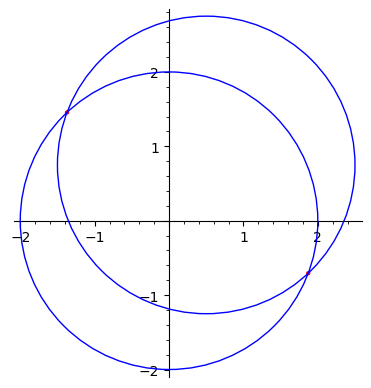

In [86]:
cercle_intersection(0,0,2,0.5,0.75,2)

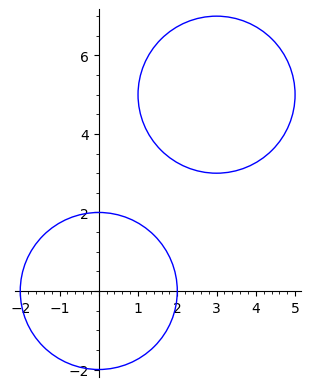

In [87]:
cercle_intersection(0,0,2,3,5,2)


L'interaction suivante permet de tester votre fonction

In [88]:
@interact
def interact_cercle_intersection(x1 = slider(-5,5), y1 = slider(-5,5), r1 = slider(1,5), x2 = slider(-5,5), y2 = slider(-5,5), r2 = slider(1,5)):
    show(cercle_intersection(x1,y1,r1,x2,y2,r2))

Interactive function <function interact_cercle_intersection at 0x7f6e6b0dfa60> with 6 widgets
  x1: TransformI…

Il est aussi possible de dessiner des ellipses dans sage.

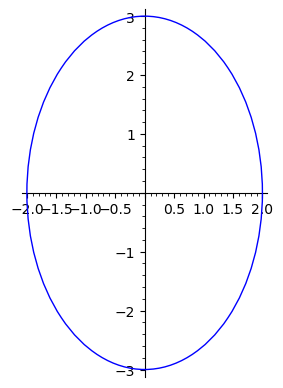

In [89]:
ellipse((0,0),2,3)

On considère des ellipses dont les axes sont parallèles aux axes du repères. L'ellipse est alors caractérisée par son centre $(x_0, y_0)$ et ses deux rayons $a$, et $b$ par l'équation

$$\frac{(x - x_0)^2}{a^2} + \frac{(y - y_0)^2}{b^2} = 1$$

En particulier, si on a $a = b$, on retrouve l'équation du cercle. 

**Reprenez l'exercice précédent en remplaçant le deuxième cercle par une ellispe :**

* Ecrivez une fonction qui trouve les points d'intersection et dessine le cercle, l'ellipse et les points.
* Créez une interaction comme dans l'exemple précédent.


In [94]:
def cercleEllipse_intersection(x1, y1, r1, x2, y2, a2, b2):
    """
    Renvoie l'affichage d'un cercle et d'une ellipse et de leurs points d'intersections
    Input :
    - x1, l'abscisse du centre du premier cercle
    - y1, l'ordonnée du centre du premier cercle
    - r1, le rayon du premier cercle
    - x2, l'abscisse du centre du deuxième cercle
    - y2, l'ordonnée du centre de l'éllipse
    - a2, un rayon de l'éllipse
    - b2, l'autre rayon de l'éllipse
    Output :
    un plot contenant un cercle et une ellipse et leurs points d'inetrsection (s'ils sont dans l'espace réel)
    """
    var('x y')
    s = solve([(x-x1)**2+(y-y1)**2==r1**2, (x-x2)**2/a2**2+(y-y2)**2/b2**2==1], x,y, solution_dict=True)
    graph = circle((x1,y1),r1)+ellipse((x2,y2),a2,b2)
    for i in s:
        if i[x] and i[y] in RR:
            graph+=point2d((i[x],i[y]), color="red")
    return graph

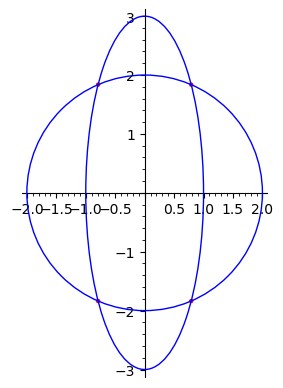

In [95]:
cercleEllipse_intersection(0,0,2,0,0,1,3)

## Résolution graphique, courbes de niveau

Soit $f(x,y)$ une fonction de deux variables. Sage permet d'afficher l'ensemble des points $(a,b)$ tel que $f(a,b) = 0$. 

L'exemple suivant affiche la courbe $y = x^2$ c'est à dire tous les points $(x,y)$ tel que $x^2 - y = 0$

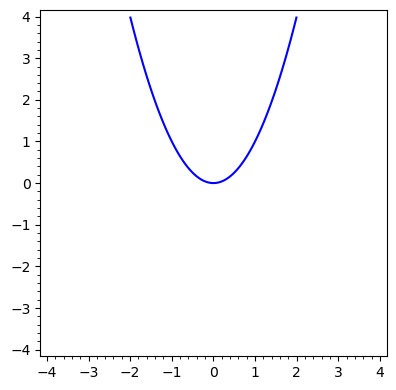

In [97]:
f(x,y) = x^2 - y
implicit_plot(f, (x, -4, 4), (y, -4, 4))

Cet autre exemple affiche tous les points $(x, y)$ tels que $x^2 - y^4 + 1 = 0$.

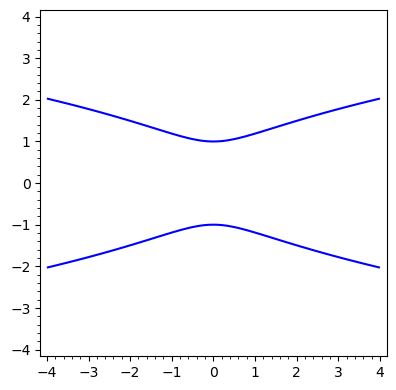

In [98]:
var('y')
f(x, y) = x^2 - y^4 + 1
implicit_plot(f, (x, -4, 4), (y, -4, 4))

**Utilisez `implicit_plot` pour afficher un cercle de rayon 1.**

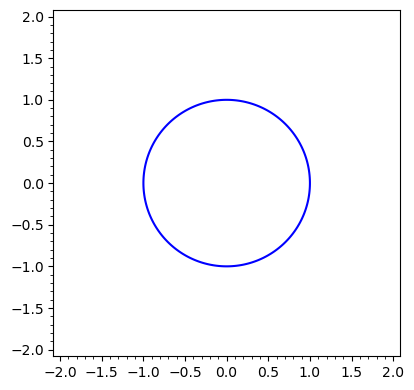

In [101]:
var('x y')
f(x, y) = x^2 + y^2-1
implicit_plot(f, (x, -2, 2), (y, -2, 2))

On peut utiliser implicit plot pour "se déplacer" à travers les coupes une surface 3d. Voilà par exemple une sphère (équation $x^2 + y^2 + z^2 - r^2 = 0$).

In [102]:
@interact 
def sphere(r = slider(1,4), z = slider(-4,4)):
    show(implicit_plot(x^2 + y^2 + z^2 - r^2, (x,-4,4), (y,-4,4)))

Interactive function <function sphere at 0x7f6e6b2424c0> with 2 widgets
  r: TransformIntSlider(value=1, descr…

Créez une iteractio pour voir les coupes d'un cône d'équation $x^2 + y^2 - z^2 = 0$

In [106]:
@interact 
def cone(z = slider(0,10)):
    show(implicit_plot(x^2 + y^2 - (z)^2, (x,-4,4), (y,-4,4)))

Interactive function <function cone at 0x7f6e6aa81310> with 1 widget
  z: TransformIntSlider(value=0, descript…

Enfin, on peut faire des affichages en 3 dimension.

In [109]:
var('x y z')
implicit_plot3d(x^2 + y^2 + z^2 - 4, (x,-4,4), (y,-4,4), (z,-4,4))

Graphics3d Object

Malheureusement, l'affichage 3d n'est pas compatible avec interact !

**Affichez un cone d'équation $x^2 + y^2 - z^2 = 0$ ainsi qu'une autre surface avec l'équation de votre choix**

## Equation différentielle

Sage permet aussi de résoudre des équations différentielles. **Exécutez l'exemple suivant.**

In [6]:
var('t')
f = function('f')(t)
equation_differentielle = (diff(f, t) == f)
sol = desolve(equation_differentielle, f, ics=[0, 1])
print(sol)

e^t


Expliquons un peu cet exemple. Ici, on commence par déclarer une variable $t$ et une fonction $f$ dépendant de $t$. La fonction $f(t)$ est ainsi définie symboliquement et on peut l'utiliser pour écrire notre équation différentielle. 

La fonction `diff(f,t)` permet de dériver $f$ par rapport à $t$. Pour obtenir une dérivée d'ordre supérieur, il suffit d'écrire `diff(f,t,2)` pour l'ordre 2 par exemple. De plus, le terme `ics` correspond à la définition des conditions initiales (Initial Conditions). La première valeur de la liste est la valeur initiale de $t$ et la seconde celle de $f(t)$.

**Résolvez l'équation différentielle $f''(t) = 3 f(t) - 4$  avec comme conditions initiales : $t = 0$,  $f(0) =  1$ et $f'(0) =0$.**

In [7]:
var('t')
f = function('f')(t)
equation_differentielle = (diff(f, t,2) == 3*f-4)
sol = desolve(equation_differentielle, f, ics=[0, 1, 0])
print(sol)

-1/6*e^(sqrt(3)*t) - 1/6*e^(-sqrt(3)*t) + 4/3


Nous propopns dans ce petit exercice de résoudre le problème suivant : une masse est accrochée à un ressort selon le schéma suivant 

|Mur|--/\/\/\/\/\--($M$)

On note $f(t)$ la position de la masse à l'instant $t$.
Le ressort a les caractéristiques suivantes :

 * il est au repos lorsque la masse est à une distance $d>0$ du bord
 * et il possède une raideur $k>0$

L'équation modèle vérifiée par $f(t)$, en supposant que la masse glisse
parfaitement, est : $f^{''}(t) = -k(f(t)-d)$.

**Résolvez cette équation et affichez la solution (pour les paramètres, prenez $d=1$ et $k=1$)**

Remarque : que devez-vous choisir comme conditions initiales ?

In [19]:
var('t')
f = function('f')(t)
equation_differentielle = (diff(f, t,2) == -1*(f-1))
sol = desolve(equation_differentielle, f, ics=[0, 0, 0])
f = sol
print(sol)

-cos(t) + 1


Creez un affichage simple (par exemple en dessinant la masse avec un cercle à l'intérieur d'un cadre plus large) permettant de voir la masse bouger au cours du temps.


/tmp/ipykernel_942/2477261075.py:1: DeprecationWarning: Substitution using function-call syntax and unnamed arguments is deprecated and will be removed from a future release of Sage; you can use named arguments instead, like EXPR(x=..., y=...)
See http://trac.sagemath.org/5930 for details.
  animate([point2d((i,f(i/Integer(5)))) for i in range(Integer(0),Integer(50))]).show()


Animation with 50 frames
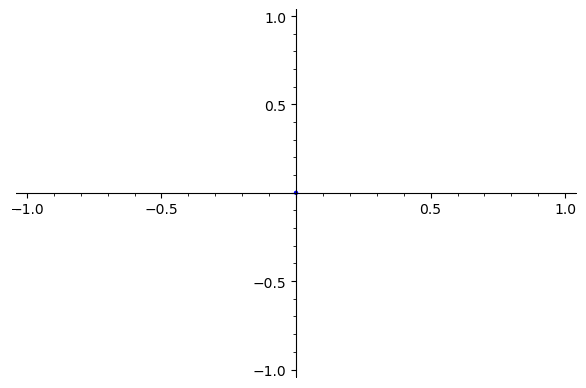

In [26]:
animate([point2d((i,f(i/5))) for i in range(0,50)]).show()

## Simulation d'un système à 2 masses oscillantes.

Nous allons voir comment utiliser Sage pour faire une *résolution numérique* approchée
d'un système d'équations.

**Problème**

On étudie le cas de 2 masses liées entres elles par deux ressorts comme représenté ci-dessous :

|Mur|--/\/\/\/\/\--($M_1$)--/\/\/\/\/\--($M_2$)

On note $x_1(t)$ et $x_2(t)$ les positions des masses $M_1$ et $M_2$.
Les deux ressorts ont les caractéristiques suivantes :
* le premier ressort, de raideur $k_1$, est au repos lorsque sa longueur est égale à $d_1$,
* le second ressort, de raideur $k_2$, est au repos lorsque sa longueur est égale à $d_2$.

Les équations vérifiées par $x_1$ et $x_2$ sont alors :
$$\begin{cases}
x''_1(t) = -k_1 (x_1 - d_1) + k_2 (x_2 - x_1 - d_2)\\[8pt]
x''_2(t) = -k_2 (x_2 - x_1 - d_2)
\end{cases}$$

On cherche à évaluer la position des deux ressorts au cours du temps.

**Comment faire ?**

Nous allons utiliser la fonction de Sage `desolve_system_rk4`. Celle-ci est conçue
pour résoudre des systèmes d'équations présentés de la façon suivante :

$$\begin{cases}
    a'_1(t) = \dots \\[8pt]
    a'_2(t) = \dots \\[8pt]
    a'_3(t) = \dots \\[8pt]
    \dots
\end{cases}$$

Ça ne correspond pas tout à fait à notre système. Le premier travail est donc
de *ré-écrire* notre problème différement. On introduit deux nouvelles variables :
$v_1 = x_1'$ et $v_2 = x_2'$.

**Sur papier**. Posez $a_1 = x_1$, $a_2 = x_2$, $a_3 = v_1$ et $a_4 = v_2$ puis
écrivez un système d'équations compatibles avec `desolve_system_rk4`. C'est-à-dire :

$$
\begin{cases}
    a'_1(t) = \dots \\[8pt]
    a'_2(t) = \dots \\[8pt]
    a'_3(t) = \dots \\[8pt]
    a'_4(t) = \dots
\end{cases}
$$

où vous n'utilisez dans la partie droite que les variables $a_1$, $a_2$, $a_3$ et $a_4$
(pas le droit d'écrire $a_i'$ ou $a_i''$ dans la partie droite) et les paramètres
$k_1$, $k_2$, $d_1$, $d_2$. Remarque : vous avez bien sûr besoin de l'équation
différentielle présentée au début.

**Passons de l'expression sur papier à la résolution sur machine**

On commence par définir les variables Python dont nous aurons besoin :
 * $a_1$, $\dots$, $a_4$ ainsi que $t$ sont des variables formelles ;
 * $k_1$, $k_2$, $d_1$, $d_2$ sont des constantes liées aux ressorts :
   on les met tous à 1 (il faudrait les initialiser avec les valeurs
   réelles des ressorts qu'on veut modéliser).


In [22]:
var('a1, a2, a3, a4, t')
k1, k2, d1, d2 = 1, 1, 1, 1

Exécutez la cellule suivante, lisez la documentation de la fonction et essayez d'identifer les différents paramètres.

In [24]:
desolve_system_rk4?

* le premier paramètre `des` correspond à la partie **droite**
  du système d'équations. C'est la partie que vous venez de trouver.
  Ce sera donc une **liste Python** dont la première valeur sera
  **l'expression** de $a_1'$, puis la deuxième l'expression de $a_2'$, etc.
* le second paramètre `vars` correspond aux variables de la partie
  **gauche** du système. Ce sera donc la **liste Python** `[a1, a2, a3, a4]`
* le paramètre `ivar` sert à déclarer la variable supplémentaire $t$
* le paramètre `ics` correspond aux conditions initiales. C'est une
  **liste python** dont la première valeur est la valeur initiale de $t$,
  puis de $a_1$, puis $a_2$, etc. On veut que commencer tel que le premier
  ressort soit à **distance 1** et le second ressort à **distance 3**,
  les deux ont une vitesse initiale nulle.
* le paramètre `end_points` donne la valeur de $t$ à laquelle on arrêtera
  le calcul. On choisit $t = 10$.
* le paramètre `step` donne la taille de chaque pas de calcul, on choisit $0.5$.

Ci-dessous, on vous initialise une partie des paramètres, **exécutez-la**.
Dans la cellule suivante, **initialisez les paramètres manquants `des` et `ics`**
pour que la cellule d'appel à la fonction `desolve_system_rk4` fonctionne.

In [25]:
vars = [a1, a2, a3, a4]
ivar = t
end_points = 10
step = 0.5

In [61]:
des = [a3, a4, -k1*(a1-d1)+k2*(a2-a1-d2), -k2*(a2-a1-d2)]
ics = [0, 1, 3, 0, 0]

In [62]:
R = desolve_system_rk4(des=des, vars=vars, ivar=ivar, ics=ics,  end_points=end_points, step=step)

Vérifiez dans la cellule suivante que `R` est bien une liste de taille 21.

In [63]:
type(R)

<class 'list'>

In [64]:
len(R)

21

**Que contient `R` ?** On a fait une résolution numérique, on n'obtient donc pas
un résultat exact sous forme de fonction. `R` est une **liste de liste**.
Par exemple, on a :

In [65]:
R[0] # au temps 0, a_1 = 1, a_2 = 3, a_3 = 0, a_4 = 0

[0, 1, 3, 0, 0]

In [66]:
R[1] # au temps 0.5, ...

[0.5, 1.1171875, 2.880208333333333, 0.4374999999999999, -0.4583333333333333]

In [67]:
R[2] # au temps 1, ...

[1.0,
 1.383538140190972,
 2.577996148003472,
 0.5602213541666667,
 -0.704318576388889]

In [68]:
R[3] # au temps 3,...

[1.5,
 1.602476331922743,
 2.227888195602982,
 0.2542102955005787,
 -0.6514131051522714]

Les valeurs qui nous intéressent sont celles de $x_1$ et $x_2$,
c'est-à-dire $a_1$ et $a_2$. On cherche à faire une interaction
montrant le mouvement des ressorts.

**Complétez la fonction Python `dessine_masse`** qui prend en paramètre
les positions des deux masses et les dessinent à l'intérieur d'un cadre. 

Puis **créez une interaction** montrant le mouvement des masses en utilisant la liste $R$ des positions au cours
du temps.

In [86]:
def dessine_masses(x1, x2):
    """
    Dessinent les deux masses à l'intérieur d'un cadre
    Input :
    - x1 la position de m1
    - x2 la position de m2
    Output : un dessin représentant les deux masses à l'intérieur d'un cadre
    """
    return circle((x1,0),0.25, fill=True)+circle((x2,0),0.25, fill=True)+line2d([(0,1),(5,1),(5,-1),(0,-1),(0,1)] )


Animation with 21 frames
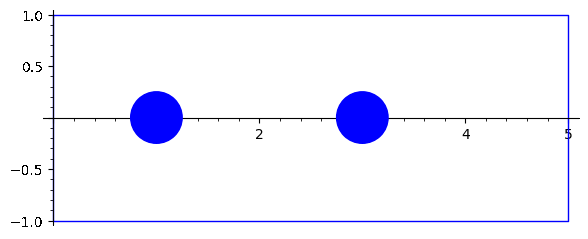

In [87]:
animate([dessine_masses(s[1], s[2]) for s in R]).show()